[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/omarcevi/pytorch-finance-workshop/blob/main/notebooks/workshop_solution.ipynb)

# Bringing AI to Financial Data (Solution Notebook)
**Işık IEEE Computer Society — PyTorch Workshop**
📍 Işık University Şile Campus, DMF-214 · 🗓️ Wednesday 18 November 2026, 16:30–18:45
🔗 **Step-by-step guide:** [omarcevi.dev/workshops/pytorch-finance-workshop](https://omarcevi.dev/workshops/pytorch-finance-workshop/)

> ⚠️ **Important (Not Investment Advice):** All code, models and analysis in this workshop are for **machine learning and PyTorch education** only. Nothing here is investment advice, and these models **must not** be used for real trading decisions.

### How this notebook works
| | |
|---|---|
| ✏️ **TODO cells** | Replace the `raise NotImplementedError(...)` line with your code, then run the cell. |
| ✅ **Checks** | Every TODO cell ends with a check that tells you whether your code is right, and what to fix if not. |
| 💡 **Hints** and 👀 **solutions** | Under each TODO in the starter notebook; click to open. |
| 🔄 **Catch up** | The first cell of each part rebuilds everything up to that point, if you fell behind or your runtime restarted. |

### ⚙️ Setup: run this first
Run the cell below before anything else (click ▶). It downloads the helper module (`workshop_utils.py`), imports PyTorch and friends, and fixes the random seeds so results come out the same on every computer. Its code is hidden; click **Show code** if you're curious.

In [1]:
# @title ⚙️ Setup: run this first { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from workshop_utils import (
    DEFAULT_TICKERS,
    FEATURE_COLS,
    GRUModel,
    LSTMModel,
    PriceWindowDataset,
    SlidingWindowDataset,
    TinyTransformerModel,
    backtest_with_costs,
    build_features,
    catch_up_part_1,
    catch_up_part_2,
    catch_up_part_3,
    catch_up_part_4,
    catch_up_part_5,
    catch_up_part_6,
    chronological_split,
    compute_rsi,
    fit_scaler_on_train,
    load_prices,
    plot_chronological_split,
    plot_direction_results,
    plot_ohlcv,
    plot_price_deception,
    plot_training_curves,
    plot_zoom_and_lag,
    set_seed,
    train_direction_classifier,
    train_price_lstm,
    walk_forward_evaluation,
)
from workshop_utils import (
    check_todo_1, check_todo_2, check_todo_3, check_todo_4, check_todo_5,
    check_todo_6, check_todo_7, check_todo_8, check_todo_9, setup_notebook,
)

setup_notebook()
set_seed(42)
print(f"PyTorch version: {torch.__version__} | Device: CPU")

PyTorch version: 2.15.0 | Device: CPU


---
## Part 0 · Intro: Could We Make Money with This Chart?
*⏱️ Live session: 16:30–16:40*

Search the web for *"stock price prediction with LSTM"* and you will almost always find a chart like the one below: the blue line is the actual price, the red dashed line is the AI model's prediction. The two lines sit almost on top of each other!

So **could we really make money with this model?** Or is there a subtle illusion right in front of our eyes? We keep the answer until Part 4 — first, let's build this model from scratch with our own hands.

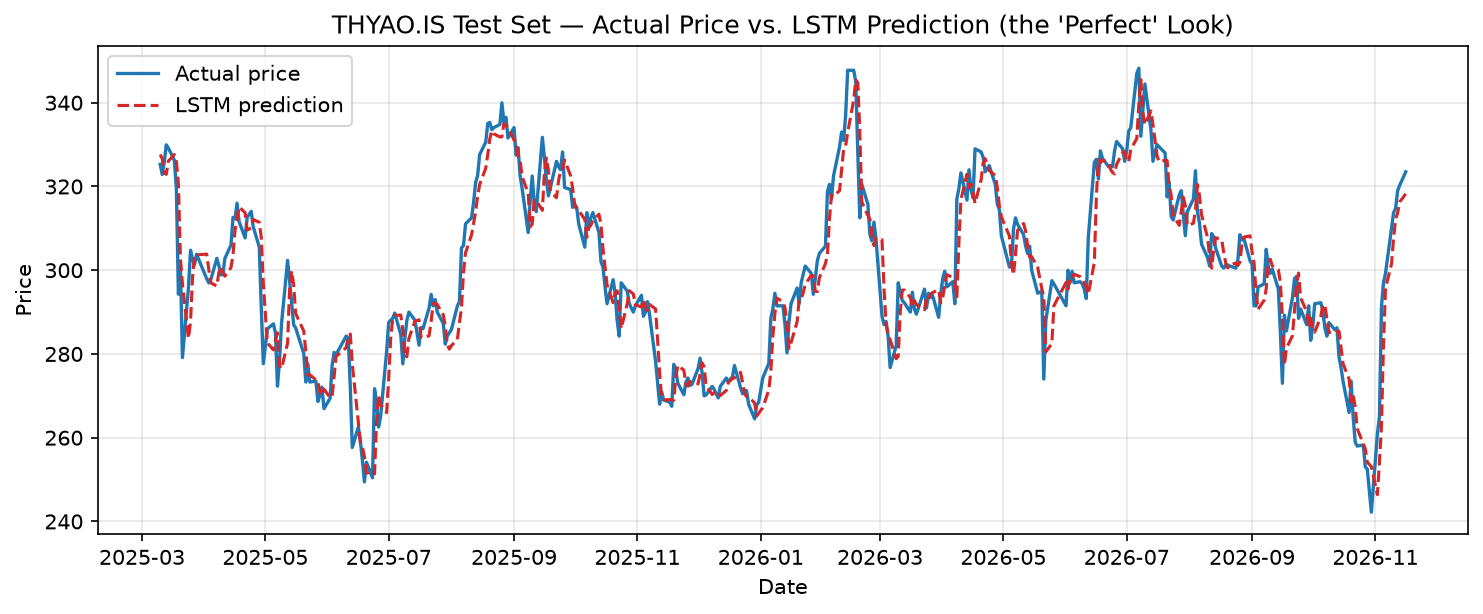

In [2]:
# @title 🎣 The chart we'll explain in Part 4 { display-mode: "form" }
# A preview of the test-set output of the LSTM price model we will train in Part 4
import contextlib, io, pathlib
from IPython.display import Image, display
from workshop_utils import catch_up_part_4, plot_price_deception

_hook_candidates = [
    pathlib.Path("docs/hook_preview.png"),
    pathlib.Path("../docs/hook_preview.png"),
    pathlib.Path("/content/pytorch-finance-workshop/docs/hook_preview.png"),
]
_hook_img = next((p for p in _hook_candidates if p.exists()), None)
try:
    # Colab has no docs/ folder: show the pre-generated image from GitHub
    display(Image(filename=str(_hook_img), width=780) if _hook_img else Image(url="https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/docs/hook_preview.png", embed=True, width=780))
except Exception:
    # No network either: build the chart here, hiding the output so the Part 4 answer (the MAE values) stays hidden
    with contextlib.redirect_stdout(io.StringIO()):
        _s4 = catch_up_part_4("THYAO.IS")
    plot_price_deception(_s4["test_dates"], _s4["price_res"]["actual_prices"], _s4["price_res"]["predicted_prices"])
    plt.show()

---
## Part 1 · Setup and Data
*⏱️ Live session: 16:40–16:55*

In financial time series each trading day is summarised by five numbers (**OHLCV**): **O**pen, **H**igh (the day's highest price), **L**ow (the day's lowest price), **C**lose and **V**olume (trading volume). Companies pay dividends and split their shares over time, so instead of raw prices we use prices adjusted for dividends and splits (**auto-adjusted**), so that no artificial price drops show up in the past.

> 💡 **Fallen behind?** Run the **"🔄 Catch up"** cell at the start of each part to create every variable needed up to that part with one click.

In [3]:
# @title 🔄 Catch up: Part 1 (run this if your runtime was reset) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from workshop_utils import FEATURE_COLS, set_seed
from workshop_utils import (
    check_todo_1, check_todo_2, check_todo_3, check_todo_4, check_todo_5,
    check_todo_6, check_todo_7, check_todo_8, check_todo_9, setup_notebook,
)
setup_notebook()
from workshop_utils import load_prices, plot_ohlcv
set_seed(42)
TICKER = "THYAO.IS"
print("✅ Part 1 environment ready.")

✅ Part 1 environment ready.


`load_prices` first tries to download the data live from Yahoo Finance (`yfinance`); if the campus network hits a rate limit, it automatically loads the snapshot data instead. Let's download Turkish Airlines (`THYAO.IS`) and look at its first and last rows.

In [4]:
TICKER = "THYAO.IS"

# BEGIN SOLUTION: load the TICKER data into raw_df with the load_prices function
raw_df = load_prices(TICKER, start="2015-01-01", end="2026-11-17")
# END SOLUTION
check_todo_1(raw_df)

print(f"Data shape: {raw_df.shape} | Date range: {raw_df.index.min().date()} -> {raw_df.index.max().date()}")
display(raw_df.tail(5).round(2))

ℹ️ Using the snapshot data for THYAO.IS.
✅ TODO 1 looks right: 3023 days of prices, 2015-01-01 -> 2026-11-16.
Data shape: (3023, 5) | Date range: 2015-01-01 -> 2026-11-16


,Open,High,Low,Close,Volume
Date,,,,,
2026-11-10,311.50,318.25,311.00,313.75,49074691
2026-11-11,312.25,318.25,310.75,314.75,32338328
2026-11-12,315.50,325.75,315.50,319.00,48809018
2026-11-13,315.75,323.50,315.00,320.25,29607838
2026-11-16,319.75,324.50,318.50,323.50,27128552


Before feeding data to a model we should always check it visually. Let's plot the close price and the trading volume, one above the other.

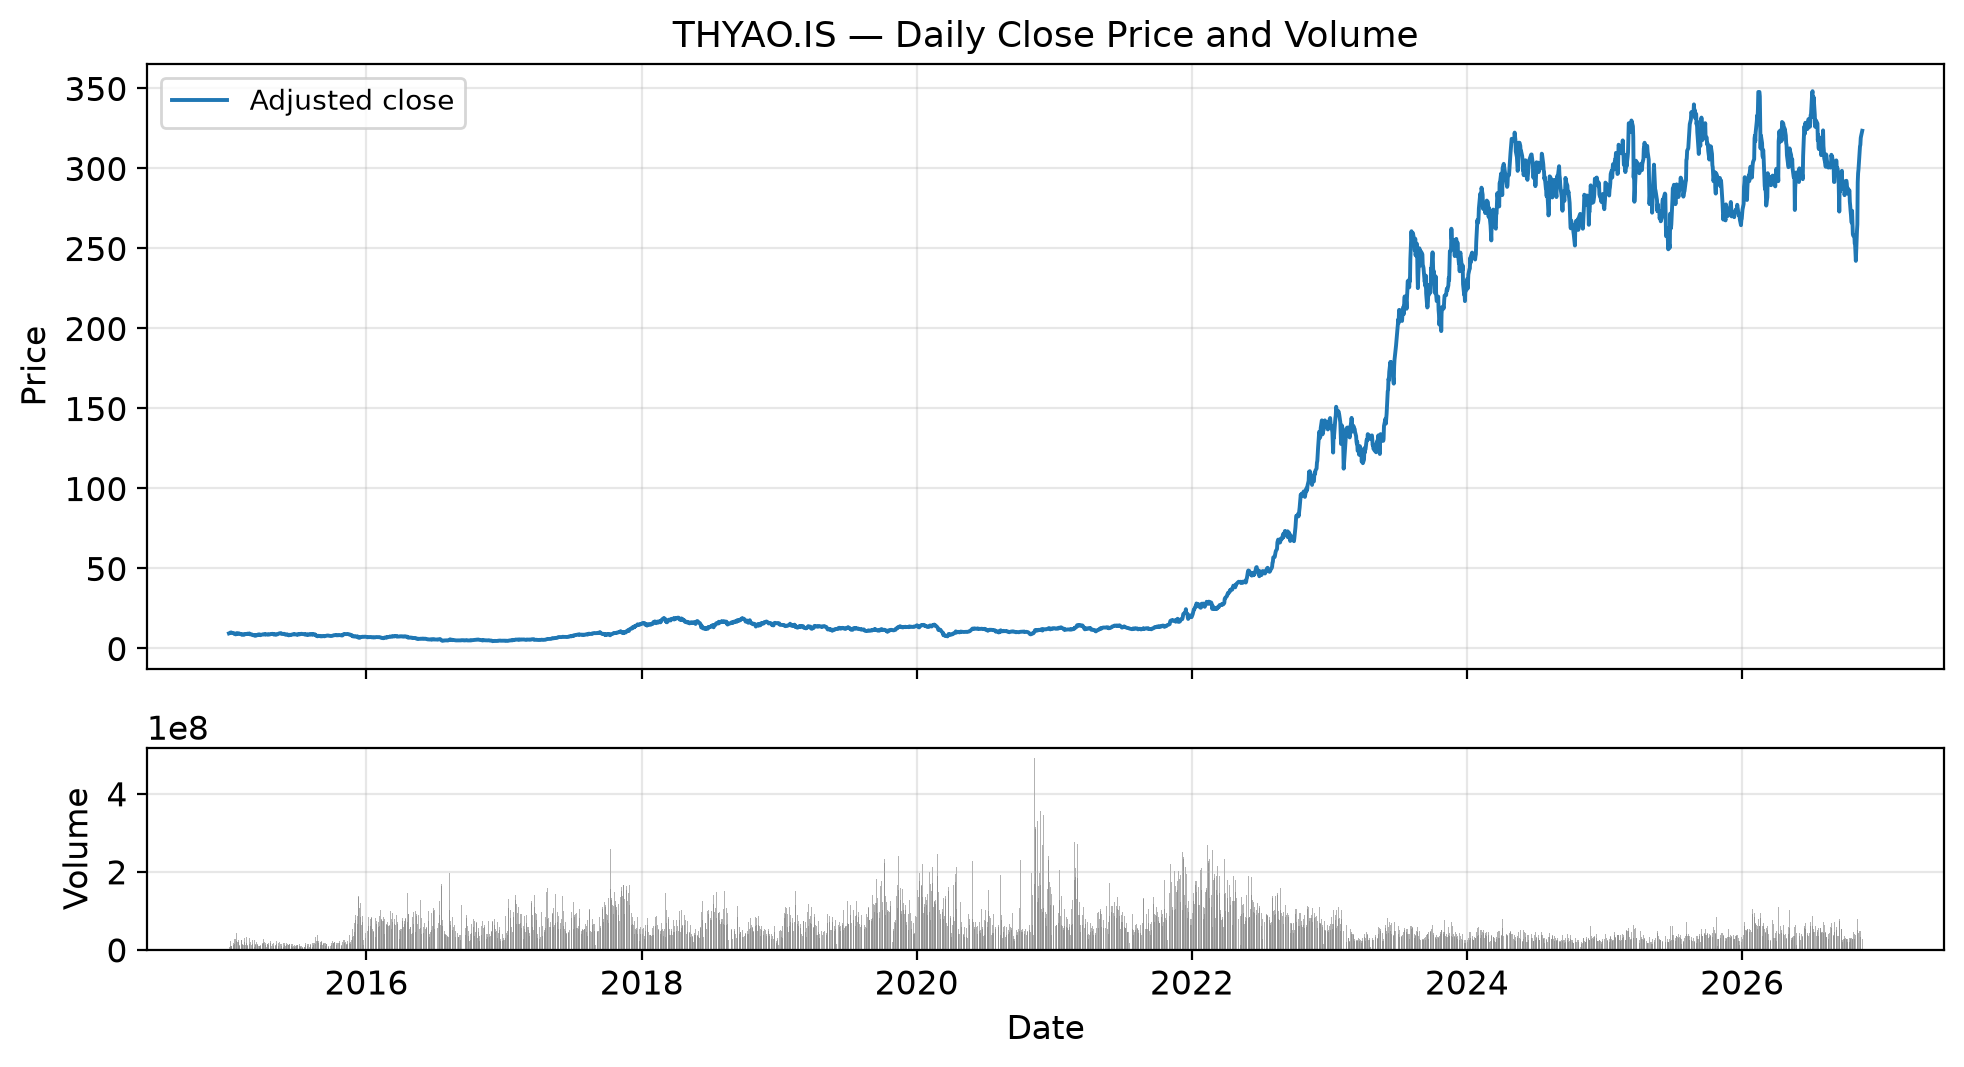

In [5]:
fig = plot_ohlcv(raw_df, ticker=TICKER)
plt.show()

---
## Part 2 · Cleaning, Features and Data Leakage
*⏱️ Live session: 16:55–17:15*

The exchange is closed at weekends and on public holidays; and because raw price series rise over time they are not **stationary** (6 TL in 2015 and 300 TL in 2026 are not on the same scale). That is why we build models not on raw prices but on scale-free features such as the **log return** ($r_t = \ln(P_t / P_{t-1})$), a moving average, volatility and RSI.

In [6]:
# @title 🔄 Catch up: Part 2 (run this if you skipped the previous part) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from workshop_utils import FEATURE_COLS, set_seed
from workshop_utils import (
    check_todo_1, check_todo_2, check_todo_3, check_todo_4, check_todo_5,
    check_todo_6, check_todo_7, check_todo_8, check_todo_9, setup_notebook,
)
setup_notebook()
from workshop_utils import catch_up_part_1, compute_rsi, chronological_split, fit_scaler_on_train, plot_chronological_split
_s1 = catch_up_part_1("THYAO.IS")
TICKER = _s1["ticker"]
raw_df = _s1["raw_df"]

ℹ️ Using the snapshot data for THYAO.IS.
✅ Part 1 ready: loaded 3023 days of OHLCV data for THYAO.IS.


When filling missing values we only carry the last past value forward (`ffill`); carrying a future value back into the past (`bfill`) means seeing the future. Then let's compute the daily log return (`log_return`), the 5-day average return (`roll_mean_5`), the 10-day volatility (`roll_std_10`) and the 14-day RSI indicator.

In [7]:
feat_df = raw_df[["Open", "High", "Low", "Close", "Volume"]].ffill().dropna().copy()

# BEGIN SOLUTION: compute the log_return, roll_mean_5 (5-day mean) and roll_std_10 (10-day std) columns
feat_df["log_return"] = np.log(feat_df["Close"] / feat_df["Close"].shift(1))
feat_df["roll_mean_5"] = feat_df["log_return"].rolling(window=5).mean()
feat_df["roll_std_10"] = feat_df["log_return"].rolling(window=10).std()
# END SOLUTION
check_todo_2(feat_df)

feat_df["rsi_14"] = compute_rsi(feat_df["Close"], period=14) / 100.0
feat_df["up_day"] = (feat_df["log_return"] > 0.0).astype(np.float32)
feat_df = feat_df.dropna().copy()
print("Feature table shape:", feat_df.shape)
display(feat_df[["Close", "log_return", "roll_mean_5", "roll_std_10", "rsi_14", "up_day"]].tail(4))

✅ TODO 2 looks right: log_return, roll_mean_5 and roll_std_10 match.
Feature table shape: (3009, 10)


,Close,log_return,roll_mean_5,roll_std_10,rsi_14,up_day
Date,,,,,,
2026-11-11,314.75,0.003182,0.015519,0.038801,0.759520,1.0
2026-11-12,319.00,0.013412,0.014292,0.038049,0.818810,1.0
2026-11-13,320.25,0.003911,0.013565,0.031575,0.829889,1.0
2026-11-16,323.50,0.010097,0.008525,0.027245,0.835131,1.0


### Chronological split (train / validation / test)
With time series, `train_test_split(..., shuffle=True)` is **never** used: testing a model trained on 2025 data against 2021 is memorising the future. We split the data in time order into **70% train**, **15% validation** and **15% test**.

✅ TODO 3 looks right: train 2106, validation 451, test 452 days, in time order.
Train: 2106 days (2015-01-21 -> 2023-04-05)
Val  : 451 days (2023-04-06 -> 2025-01-24)
Test : 452 days (2025-01-27 -> 2026-11-16)


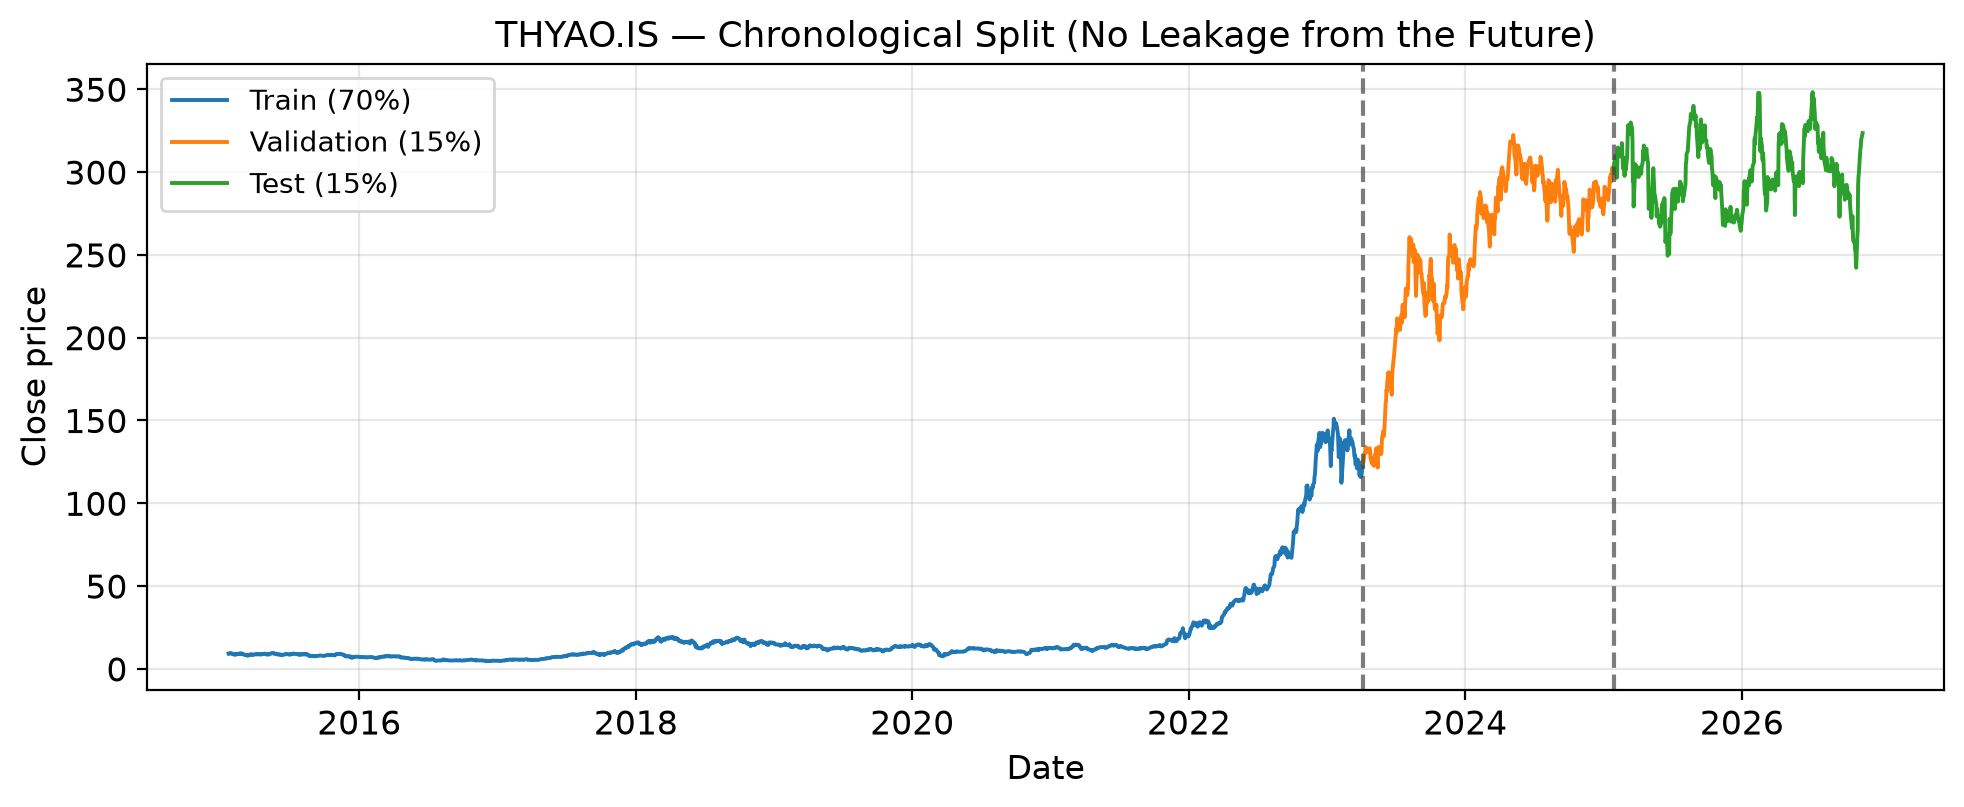

In [8]:
# BEGIN SOLUTION: split feat_df into 70% train, 15% val and 15% test with the chronological_split function
train_df, val_df, test_df = chronological_split(feat_df, train_ratio=0.70, val_ratio=0.15)
# END SOLUTION
check_todo_3(train_df, val_df, test_df, feat_df)

print(f"Train: {len(train_df)} days ({train_df.index[0].date()} -> {train_df.index[-1].date()})")
print(f"Val  : {len(val_df)} days ({val_df.index[0].date()} -> {val_df.index[-1].date()})")
print(f"Test : {len(test_df)} days ({test_df.index[0].date()} -> {test_df.index[-1].date()})")
fig = plot_chronological_split(train_df, val_df, test_df, ticker=TICKER)
plt.show()

### Why is the scaler fitted on the training data only?
When we scale features to mean 0 and standard deviation 1 (`StandardScaler`), we call `scaler.fit()` **on `train_df` only**. If we `fit()` on all of the data, the market volatility and average returns of 2025–2026 leak into the 2018 training samples (**data leakage**).

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# BEGIN SOLUTION: fit_transform the scaler on train_df[FEATURE_COLS] only; call transform on val and test
x_train = scaler.fit_transform(train_df[FEATURE_COLS].values.astype(np.float32))
x_val = scaler.transform(val_df[FEATURE_COLS].values.astype(np.float32))
x_test = scaler.transform(test_df[FEATURE_COLS].values.astype(np.float32))
# END SOLUTION
check_todo_4(x_train, x_val, x_test, train_df, val_df, test_df)

print(f"Train mean (about 0): {x_train.mean(axis=0).round(4)}")
print(f"Test mean           : {x_test.mean(axis=0).round(4)}")

✅ TODO 4 looks right: the scaler learned its mean and std from train_df only.
Train mean (about 0): [-0. -0. -0. -0.]
Test mean           : [-0.0415 -0.0932 -0.3625 -0.1527]


---
## Part 3 · PyTorch Basics: Tensor, Dataset and LSTM
*⏱️ Live session: 17:15–17:35*

PyTorch's basic building block is `torch.Tensor` (like a NumPy array, but with automatic differentiation and GPU/CPU acceleration). An LSTM expects its input as a 3-D tensor of shape **`(batch_size, seq_len, num_features)`** (number of samples, window length, number of features).

In [10]:
# @title 🔄 Catch up: Part 3 (run this if you skipped the previous part) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from workshop_utils import FEATURE_COLS, set_seed
from workshop_utils import (
    check_todo_1, check_todo_2, check_todo_3, check_todo_4, check_todo_5,
    check_todo_6, check_todo_7, check_todo_8, check_todo_9, setup_notebook,
)
setup_notebook()
from workshop_utils import catch_up_part_2, SlidingWindowDataset, LSTMModel, plot_training_curves
_s2 = catch_up_part_2("THYAO.IS")
TICKER = _s2["ticker"]
raw_df, feat_df = _s2["raw_df"], _s2["feat_df"]
train_df, val_df, test_df = _s2["train_df"], _s2["val_df"], _s2["test_df"]
scaler, x_train, x_val, x_test = _s2["scaler"], _s2["x_train"], _s2["x_val"], _s2["x_test"]

ℹ️ Using the snapshot data for THYAO.IS.
✅ Part 1 ready: loaded 3023 days of OHLCV data for THYAO.IS.
✅ Part 2 ready: train=2106, val=451, test=452 rows and 4 features scaled.


First, let's turn a small NumPy array into a PyTorch tensor and look at its `shape` and `dtype`.

In [11]:
sample_tensor = torch.tensor(x_train[:5], dtype=torch.float32)
print(f"Tensor shape: {sample_tensor.shape} | dtype: {sample_tensor.dtype}")

Tensor shape: torch.Size([5, 4]) | dtype: torch.float32


### Sliding window (`SlidingWindowDataset`) and `DataLoader`
We will give our model the features of the last **30 trading days** (`idx : idx + 30`) and have it predict the value of **day 31** (`idx + 30`).
> 📌 **Important:** Our train, validation and test split is fully chronological. Shuffling the 30-day windows *inside* the training set with `DataLoader(..., shuffle=True)` is still safe: each window keeps its own 30-day order, and shuffling helps gradient descent (SGD/Adam) learn more stably.

In [12]:
WINDOW_SIZE = 30
BATCH_SIZE = 64

y_train_ret = train_df["log_return"].values.astype(np.float32)
y_val_ret = val_df["log_return"].values.astype(np.float32)

# BEGIN SOLUTION: create train_ds and val_ds with SlidingWindowDataset and wrap them in DataLoaders (shuffle=True for train)
train_ds = SlidingWindowDataset(x_train, y_train_ret, window_size=WINDOW_SIZE)
val_ds = SlidingWindowDataset(x_val, y_val_ret, window_size=WINDOW_SIZE)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
# END SOLUTION
check_todo_5(train_ds, val_ds, train_loader, val_loader, x_train, x_val, WINDOW_SIZE)

sample_bx, sample_by = next(iter(train_loader))
print(f"Input batch shape (batch, seq_len, features): {sample_bx.shape}")
print(f"Target batch shape (batch,)                  : {sample_by.shape}")

✅ TODO 5 looks right: 2076 training windows, batches of shape (64, 30, 4).
Input batch shape (batch, seq_len, features): torch.Size([64, 30, 4])
Target batch shape (batch,)                  : torch.Size([64])


### An LSTM with `nn.Module`, following the shapes
The `nn.LSTM(input_dim, hidden_dim, batch_first=True)` layer produces a hidden state for every time step (`out` shape: `(batch, seq_len, hidden_dim)`). We take only the summary of the window's **last day** (`out[:, -1, :]`, shape `(batch, hidden_dim)`) and pass it through a linear layer (`nn.Linear(hidden_dim, 1)`).

In [13]:
class SimpleLSTM(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 32) -> None:
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # BEGIN SOLUTION: pass x through self.lstm, feed the last time step (out[:, -1, :]) to self.fc and return it with squeeze(-1)
        out, _ = self.lstm(x)
        last_step = out[:, -1, :]
        return self.fc(last_step).squeeze(-1)
        # END SOLUTION

check_todo_6(SimpleLSTM)

set_seed(42)
demo_model = SimpleLSTM(input_dim=len(FEATURE_COLS), hidden_dim=32)
with torch.no_grad():
    lstm_out, _ = demo_model.lstm(sample_bx)
    pred_out = demo_model(sample_bx)
print(f"1) Input tensor (bx)           : {sample_bx.shape}")
print(f"2) LSTM all steps (lstm_out)   : {lstm_out.shape}")
print(f"3) Last time step ([:, -1, :]) : {lstm_out[:, -1, :].shape}")
print(f"4) Model output (pred_out)     : {pred_out.shape}")

✅ TODO 6 looks right: (batch, 30, 4) -> LSTM -> last time step -> Linear -> (batch,).
1) Input tensor (bx)           : torch.Size([64, 30, 4])
2) LSTM all steps (lstm_out)   : torch.Size([64, 30, 32])
3) Last time step ([:, -1, :]) : torch.Size([64, 32])
4) Model output (pred_out)     : torch.Size([64])


### The PyTorch training loop
Every PyTorch training step runs five basic commands: `optimizer.zero_grad()` (reset old gradients), `pred = model(bx)` (forward pass), `loss = criterion(pred, by)` (compute the error), `loss.backward()` (backpropagate to get the gradients) and `optimizer.step()` (update the weights).

✅ TODO 7 looks right: train loss went from 0.001552 to 0.000646.
Last epoch (10) -> Train MSE: 0.000646 | Val MSE: 0.000509


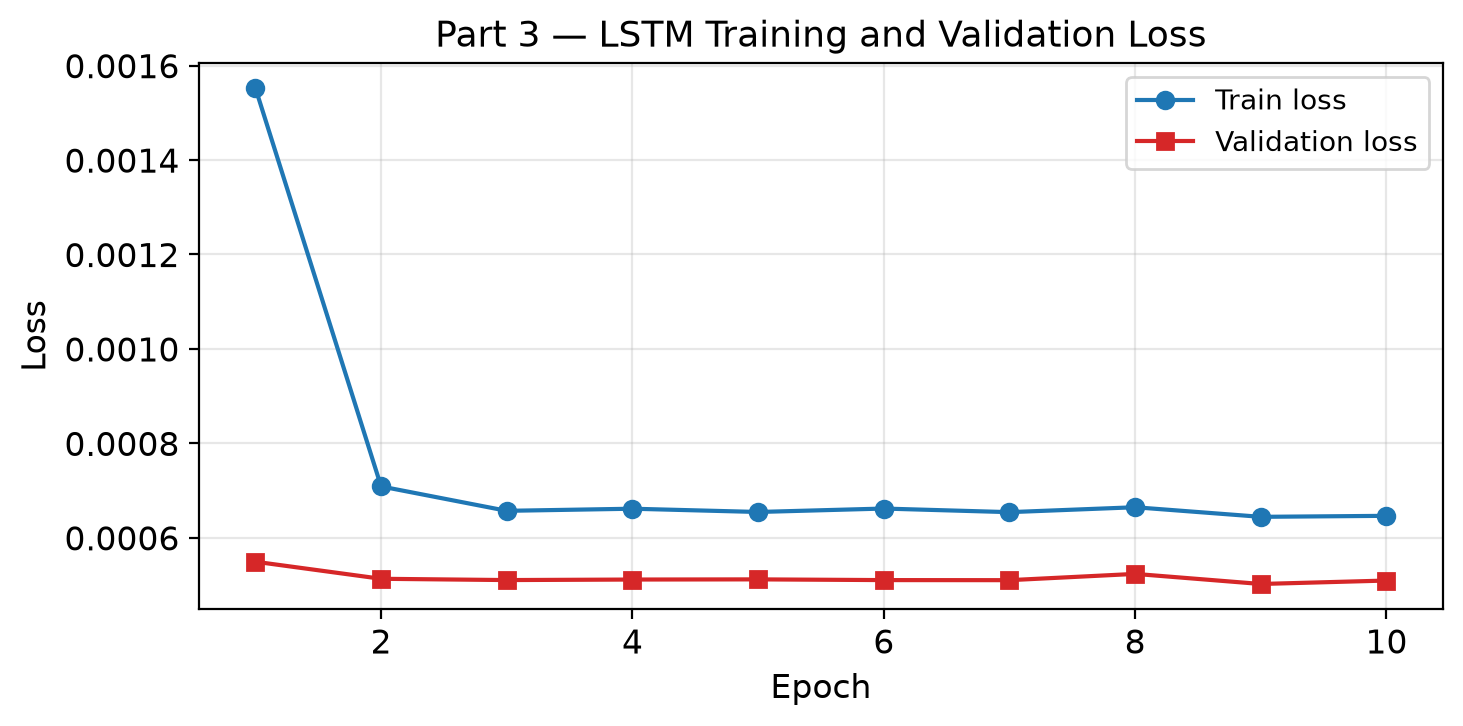

In [14]:
set_seed(42)
demo_model = SimpleLSTM(input_dim=len(FEATURE_COLS), hidden_dim=32)
optimizer = torch.optim.Adam(demo_model.parameters(), lr=0.001)
criterion = nn.MSELoss()

train_losses, val_losses = [], []
for epoch in range(10):
    demo_model.train()
    batch_losses = []
    for bx, by in train_loader:
        # BEGIN SOLUTION: write the five-step PyTorch training loop (zero_grad, forward, loss, backward, step)
        optimizer.zero_grad()
        pred = demo_model(bx)
        loss = criterion(pred, by)
        loss.backward()
        optimizer.step()
        # END SOLUTION
        batch_losses.append(loss.item())
    train_losses.append(float(np.mean(batch_losses)))

    demo_model.eval()
    with torch.no_grad():
        v_loss = np.mean([criterion(demo_model(vx), vy).item() for vx, vy in val_loader])
    val_losses.append(float(v_loss))

check_todo_7(demo_model, train_loader, train_losses)
print(f"Last epoch (10) -> Train MSE: {train_losses[-1]:.6f} | Val MSE: {val_losses[-1]:.6f}")
fig = plot_training_curves(train_losses, val_losses, title="Part 3 — LSTM Training and Validation Loss")
plt.show()

---
## ☕ Break (10 minutes)
*⏱️ Live session: 17:35–17:45*

Grab your tea or coffee! After the break we will produce the **"perfect" price prediction chart** from Part 0 and reveal the surprise behind it.

---
## Part 4 · Price Prediction and the Surprise
*⏱️ Live session: 17:45–18:05*

Now let's do what many online tutorials do: give the LSTM the **close prices** of the last 30 days and have it predict **tomorrow's close (TL)**.

> 💡 **Technical note (the second trap — activation saturation):** `THYAO.IS` was 5 TL in 2015 and is above 300 TL in 2026. Fit one `StandardScaler` on the whole training set and test prices land at $z > 7$; the LSTM's `tanh`/`sigmoid` gates saturate and the output locks into a flat line. To avoid this trap, `PriceWindowDataset` normalises each 30-day window relative to its own first day (`price / first_day - 1`) and converts the prediction back to TL.

In [15]:
# @title 🔄 Catch up: Part 4 (run this for a clean start after the break) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from workshop_utils import FEATURE_COLS, set_seed
from workshop_utils import (
    check_todo_1, check_todo_2, check_todo_3, check_todo_4, check_todo_5,
    check_todo_6, check_todo_7, check_todo_8, check_todo_9, setup_notebook,
)
setup_notebook()
from workshop_utils import catch_up_part_3, train_price_lstm, plot_price_deception, plot_zoom_and_lag
_s3 = catch_up_part_3("THYAO.IS")
TICKER = _s3["ticker"]
train_df, val_df, test_df = _s3["train_df"], _s3["val_df"], _s3["test_df"]
WINDOW_SIZE = _s3["window_size"]

ℹ️ Using the snapshot data for THYAO.IS.
✅ Part 1 ready: loaded 3023 days of OHLCV data for THYAO.IS.
✅ Part 2 ready: train=2106, val=451, test=452 rows and 4 features scaled.
✅ Part 3 ready: window size=30, training samples=2076.


Let's train our price model for 15 epochs and plot the actual test prices and the LSTM predictions on the same chart.

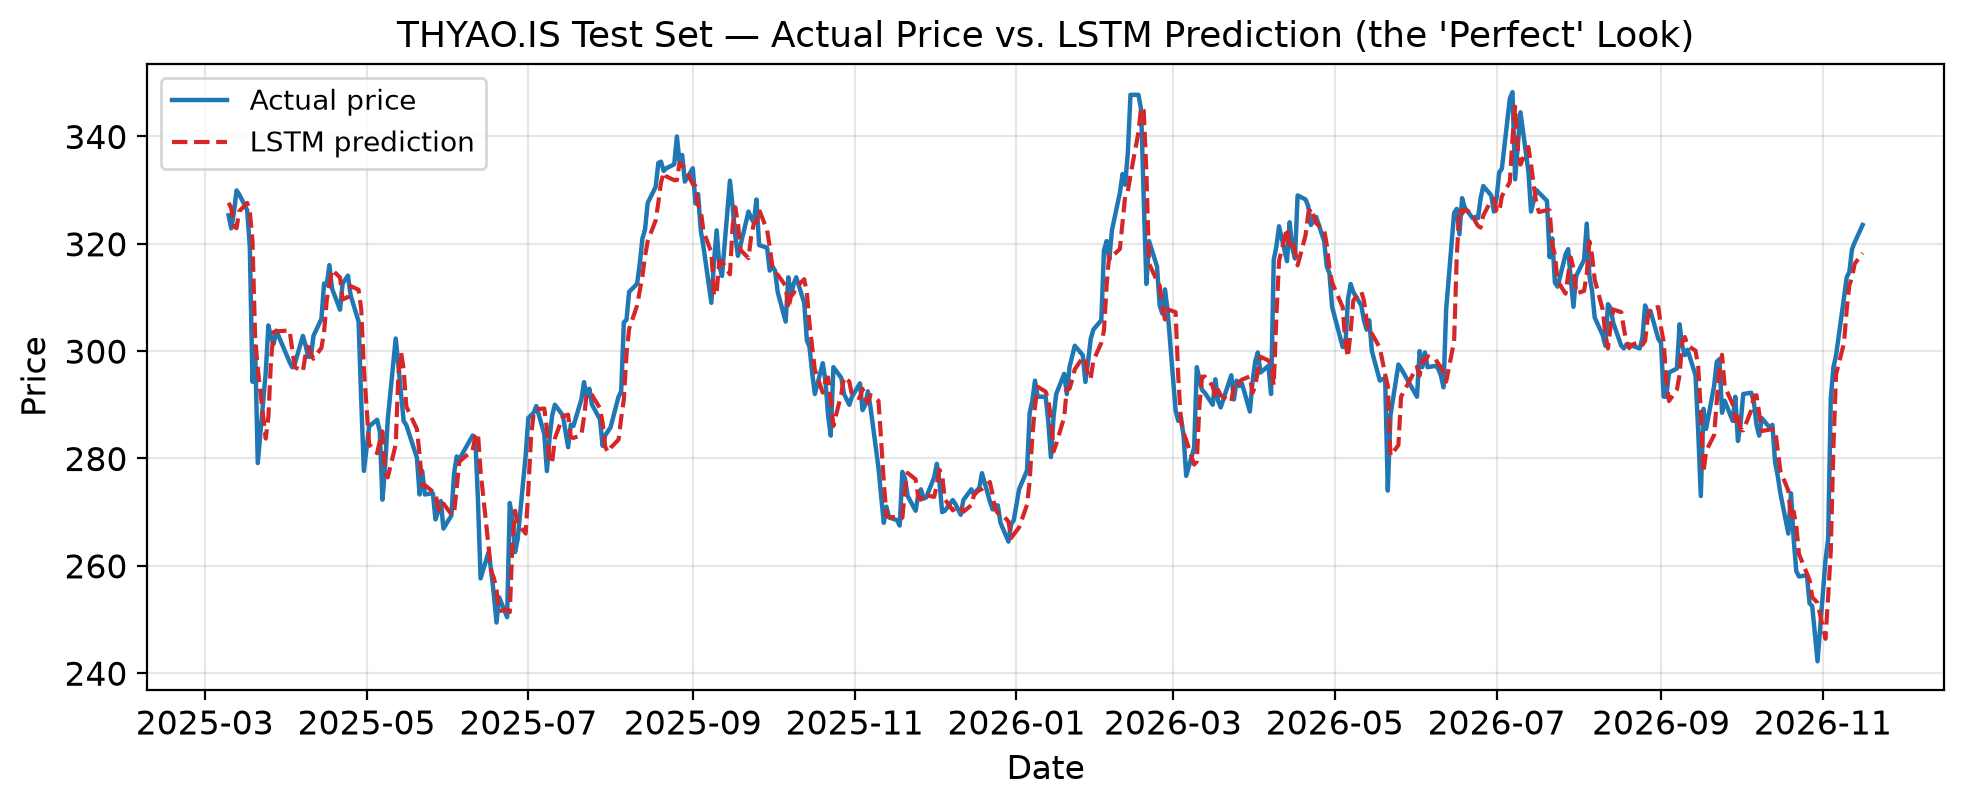

In [16]:
price_res = train_price_lstm(
    train_df["Close"].values,
    val_df["Close"].values,
    test_df["Close"].values,
    window_size=WINDOW_SIZE,
    epochs=15,
    seed=42,
)
test_dates = test_df.index[WINDOW_SIZE:]
actual_prices = price_res["actual_prices"]
predicted_prices = price_res["predicted_prices"]
naive_prices = price_res["naive_prices"]  # The last known price of each window (today's price, P_t)

fig = plot_price_deception(test_dates, actual_prices, predicted_prices, ticker=TICKER)
plt.show()

### Surprise 1: the naive baseline (*"tomorrow = today"*)
The chart above looks great, doesn't it? Now let's build the simplest baseline there is, with no AI at all (the **naive baseline**): **"tomorrow's price equals today's close ($\hat{P}_{t+1} = P_t$)."** Let's compare the two models' mean absolute error (**MAE**, in TL) and root mean squared error (**RMSE**)!

In [17]:
# BEGIN SOLUTION: compute the MAE and RMSE between actual_prices and predicted_prices, and between actual_prices and naive_prices
lstm_mae = float(np.mean(np.abs(actual_prices - predicted_prices)))
naive_mae = float(np.mean(np.abs(actual_prices - naive_prices)))
lstm_rmse = float(np.sqrt(np.mean((actual_prices - predicted_prices) ** 2)))
naive_rmse = float(np.sqrt(np.mean((actual_prices - naive_prices) ** 2)))
# END SOLUTION
check_todo_8(lstm_mae, naive_mae, lstm_rmse, naive_rmse, actual_prices, predicted_prices, naive_prices)

print(f"📊 LSTM price model     -> MAE: {lstm_mae:.2f} TL | RMSE: {lstm_rmse:.2f} TL")
print(f"📏 Naive baseline (P_t) -> MAE: {naive_mae:.2f} TL | RMSE: {naive_rmse:.2f} TL")
if naive_mae <= lstm_mae:
    print(f"👉 Result: the naive 'tomorrow = today' rule has {lstm_mae - naive_mae:.2f} TL lower error than the LSTM!")
else:
    print(f"👉 Result: this time the LSTM beats the naive rule by {naive_mae - lstm_mae:.2f} TL; check the lag chart below before celebrating.")

✅ TODO 8 looks right: LSTM MAE 5.07 vs naive MAE 4.55.
📊 LSTM price model     -> MAE: 5.07 TL | RMSE: 6.86 TL
📏 Naive baseline (P_t) -> MAE: 4.55 TL | RMSE: 6.26 TL
👉 Result: the naive 'tomorrow = today' rule has 0.52 TL lower error than the LSTM!


### Surprise 2: zoom in and a one-day lag appears
Why does the naive baseline beat the LSTM? Let's look at the last 35 trading days through a magnifying glass, and measure the correlation of the LSTM prediction with the actual price series at different lags (`Lag 0` = same day, `Lag 1` = yesterday's price).

You will see that **the LSTM is not predicting the future; it copies yesterday's price and shifts it one day to the right!** Prices are very close to a random walk ($P_{t+1} = P_t + \epsilon$), and the easiest shortcut to minimise squared error (MSE) is to predict $\hat{P}_{t+1} \approx P_t$.

Correlation of the prediction with TODAY's actual price     (Lag 0): 0.9451
Correlation of the prediction with YESTERDAY's actual price (Lag 1): 0.9915


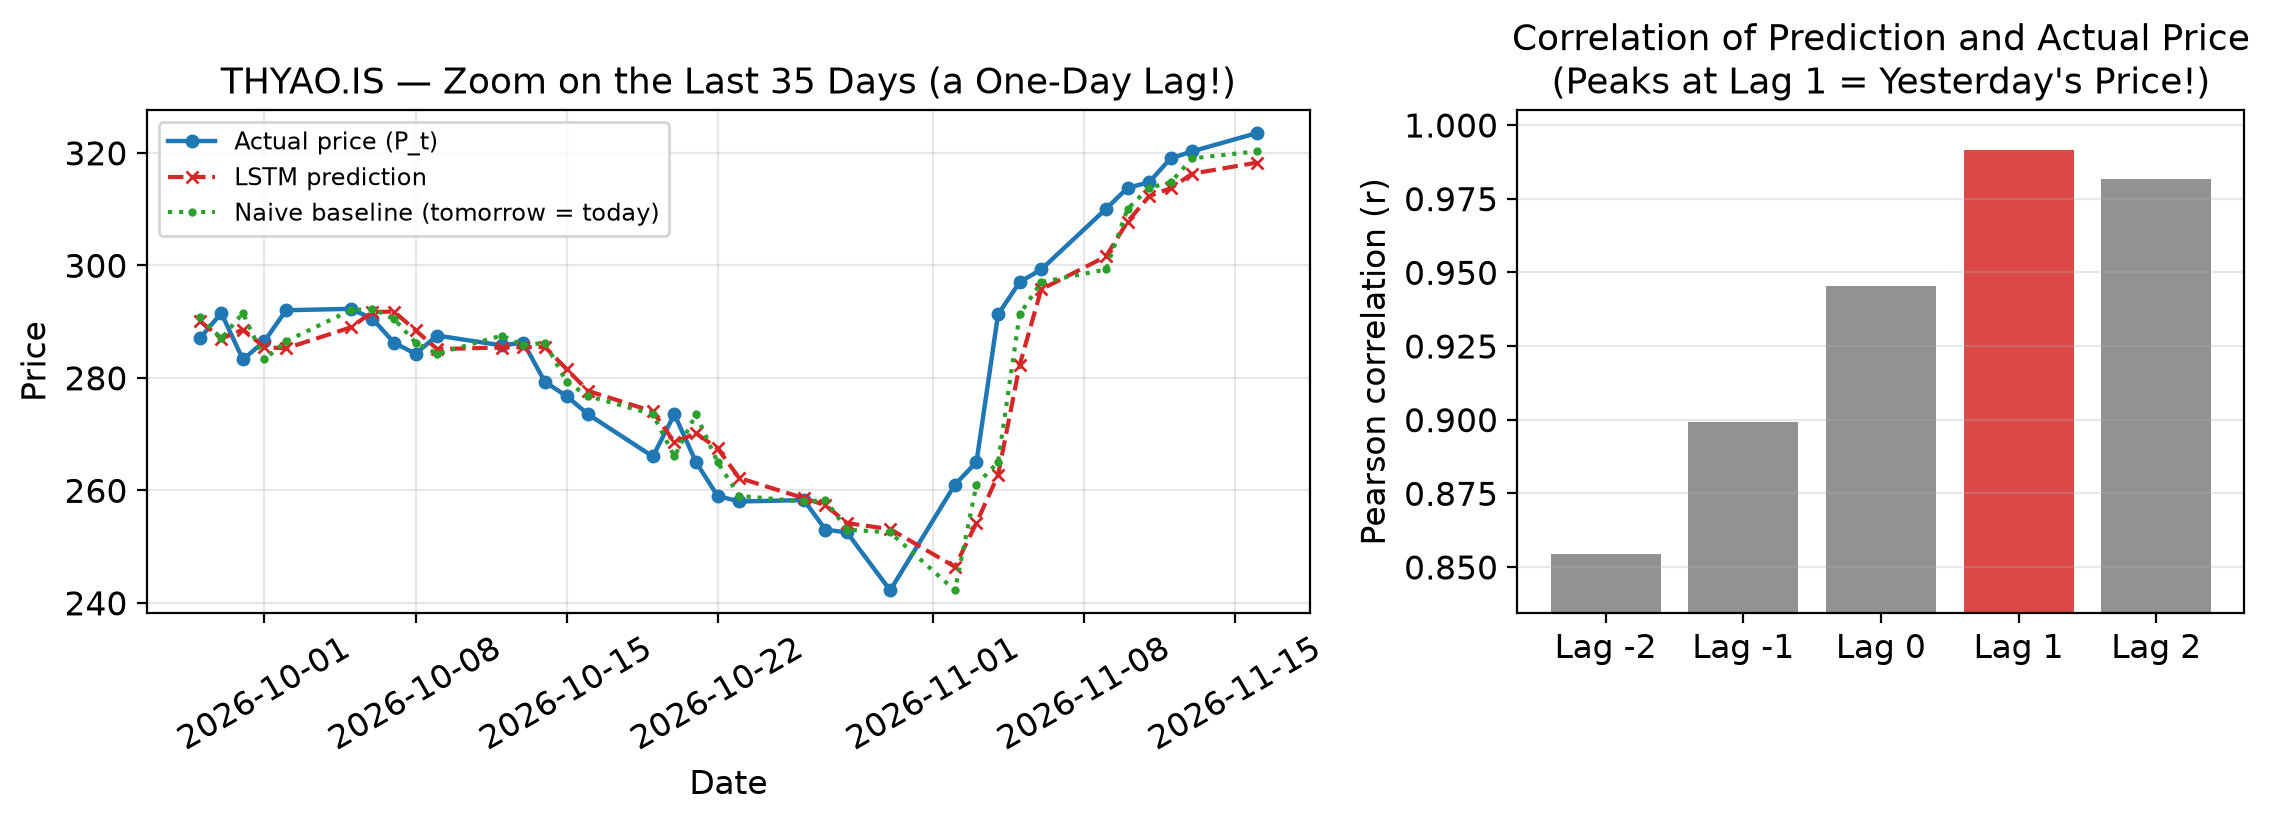

In [18]:
corr_today = float(np.corrcoef(predicted_prices[1:], actual_prices[1:])[0, 1])
corr_yesterday = float(np.corrcoef(predicted_prices[1:], actual_prices[:-1])[0, 1])
print(f"Correlation of the prediction with TODAY's actual price     (Lag 0): {corr_today:.4f}")
print(f"Correlation of the prediction with YESTERDAY's actual price (Lag 1): {corr_yesterday:.4f}")

fig = plot_zoom_and_lag(test_dates, actual_prices, predicted_prices, naive_prices, ticker=TICKER, zoom_days=35)
plt.show()

---
## Part 5 · The Right Setup: Direction Classification on Returns
*⏱️ Live session: 18:05–18:25*

To escape the copy-yesterday trap we must define the problem correctly:
1. **Input:** stationary return and technical features (`log_return`, `roll_mean_5`, `roll_std_10`, `rsi_14`).
2. **Target:** not tomorrow's price level but **tomorrow's direction** (`1` = up, $r_{t+1} > 0$; `0` = down, $r_{t+1} \le 0$).
3. **Loss function:** `nn.BCEWithLogitsLoss()` for binary classification.
4. **Baseline:** the **majority-class baseline**, which always picks the most frequent class in the training set.

In [19]:
# @title 🔄 Catch up: Part 5 (run this if you skipped the previous part) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from workshop_utils import FEATURE_COLS, set_seed
from workshop_utils import (
    check_todo_1, check_todo_2, check_todo_3, check_todo_4, check_todo_5,
    check_todo_6, check_todo_7, check_todo_8, check_todo_9, setup_notebook,
)
setup_notebook()
from workshop_utils import catch_up_part_2, train_direction_classifier, walk_forward_evaluation, plot_direction_results
_s2 = catch_up_part_2("THYAO.IS")
TICKER = _s2["ticker"]
feat_df = _s2["feat_df"]
train_df, val_df, test_df = _s2["train_df"], _s2["val_df"], _s2["test_df"]
x_train, x_val, x_test = _s2["x_train"], _s2["x_val"], _s2["x_test"]
WINDOW_SIZE = 30

ℹ️ Using the snapshot data for THYAO.IS.
✅ Part 1 ready: loaded 3023 days of OHLCV data for THYAO.IS.
✅ Part 2 ready: train=2106, val=451, test=452 rows and 4 features scaled.


Now let's train the direction classifier on the `up_day` target and compare test `Accuracy`, `Balanced Accuracy` and the `Majority Baseline`.

In [20]:
y_train_dir = train_df["up_day"].values.astype(np.float32)
y_val_dir = val_df["up_day"].values.astype(np.float32)
y_test_dir = test_df["up_day"].values.astype(np.float32)

# BEGIN SOLUTION: call the train_direction_classifier function to get the cls_res dictionary
cls_res = train_direction_classifier(
    x_train,
    y_train_dir,
    x_val,
    y_val_dir,
    x_test,
    y_test_dir,
    window_size=WINDOW_SIZE,
    epochs=15,
    seed=42,
)
# END SOLUTION
check_todo_9(cls_res, test_df, WINDOW_SIZE)

print(f"🎯 LSTM test accuracy       : {cls_res['test_acc'] * 100:.2f}%")
print(f"⚖️ LSTM balanced accuracy   : {cls_res['test_bal_acc'] * 100:.2f}%")
print(f"📏 Majority-class baseline  : {cls_res['majority_acc'] * 100:.2f}%")

✅ TODO 9 looks right: test accuracy 54.74% on 422 test days.
🎯 LSTM test accuracy       : 54.74%
⚖️ LSTM balanced accuracy   : 53.51%
📏 Majority-class baseline  : 51.90%


### Walk-forward validation, and why the result is around 50%
A single test period can come out a bit high or low by luck. For a realistic evaluation we use **walk-forward validation**: we retrain the model on 4 consecutive time periods and test each on the period that follows (the `scaler` is fitted at every step on that step's past data only).

> 🧠 **Why is honest accuracy in the 50–55% band?**
> 1. **Efficient market hypothesis:** the past daily price information everyone can see is already reflected in prices.
> 2. **Low signal-to-noise ratio:** most daily price moves come from news flow and random liquidity shocks (noise).
> 3. **Non-stationarity (regime changes):** interest rates, inflation and market dynamics change from year to year.
> *(Tip: if you see 80%+ direction accuracy on daily financial data, you have almost certainly leaked data!)*
>
> With about 420 test days, the 95% confidence interval around an accuracy near 55% is roughly ±5 points, so a few points above 50% or above the majority baseline is not evidence of an edge.

,fold,train_end_date,test_end_date,accuracy,balanced_accuracy,majority_acc
0,1,2020-11-10,2022-05-11,0.505780,0.528184,0.459538
1,2,2022-05-11,2023-11-10,0.494220,0.489759,0.479769
2,3,2023-11-10,2025-05-15,0.543353,0.520701,0.528902
3,4,2025-05-15,2026-11-13,0.523121,0.515044,0.511561


Walk-forward mean accuracy: 51.66%


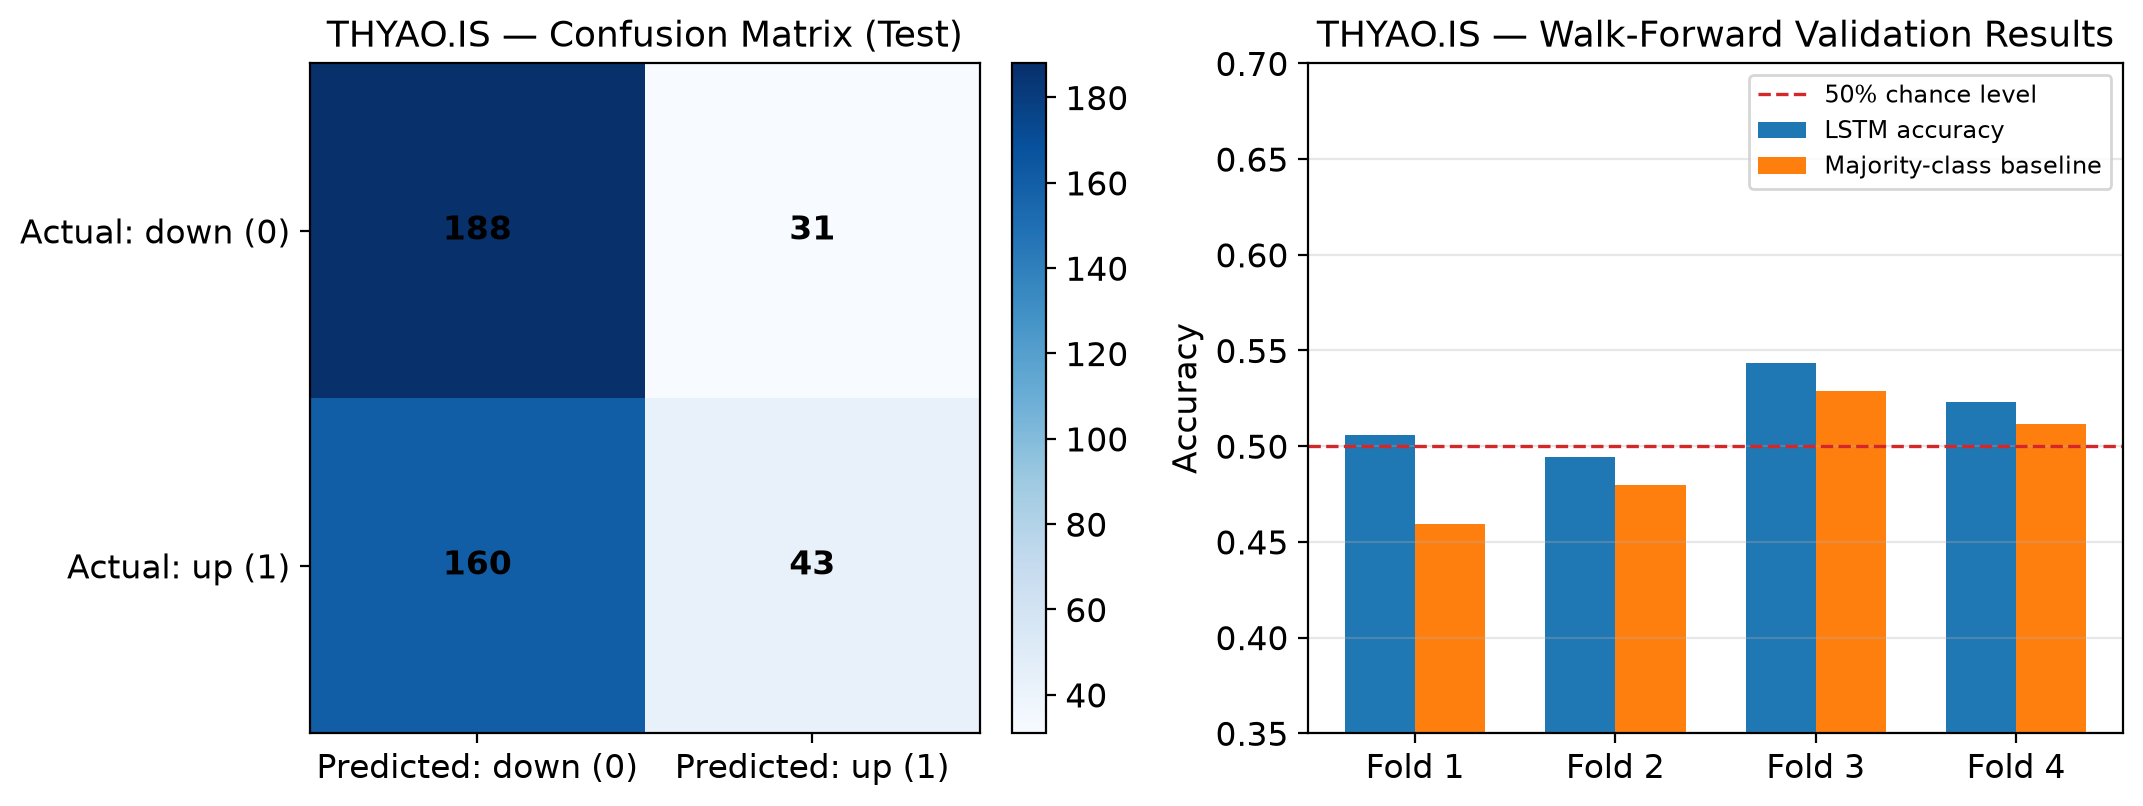

In [21]:
wf_res = walk_forward_evaluation(feat_df, FEATURE_COLS, n_splits=4, window_size=WINDOW_SIZE, epochs=10, seed=42)
wf_df = pd.DataFrame(wf_res)
display(wf_df)
print(f"Walk-forward mean accuracy: {wf_df['accuracy'].mean() * 100:.2f}%")

fig = plot_direction_results(cls_res["confusion_matrix"], wf_res, ticker=TICKER)
plt.show()

---
## Part 6 · Challenges
*⏱️ Live session: 18:25–18:40*

Your turn! Try the challenges below at your own pace. Each has a hint and a collapsed (**Show solution**) cell underneath.

In [22]:
# @title 🔄 Catch up: Part 6 (prepares every variable for the challenges) { display-mode: "form" }
import pathlib, sys, urllib.request
for _p in [pathlib.Path("src"), pathlib.Path("../src"), pathlib.Path("/content/pytorch-finance-workshop/src")]:
    if (_p / "workshop_utils.py").exists() and str(_p.resolve()) not in sys.path:
        sys.path.insert(0, str(_p.resolve()))
if not any((pathlib.Path(p) / "workshop_utils.py").exists() for p in sys.path + ["."]):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/omarcevi/pytorch-finance-workshop/main/src/workshop_utils.py",
        "workshop_utils.py",
    )
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from workshop_utils import FEATURE_COLS, set_seed
from workshop_utils import (
    check_todo_1, check_todo_2, check_todo_3, check_todo_4, check_todo_5,
    check_todo_6, check_todo_7, check_todo_8, check_todo_9, setup_notebook,
)
setup_notebook()
from workshop_utils import (
    catch_up_part_6, load_prices, build_features, chronological_split,
    fit_scaler_on_train, train_direction_classifier, backtest_with_costs,
    GRUModel, TinyTransformerModel,
)
_s6 = catch_up_part_6("THYAO.IS")
TICKER = _s6["ticker"]
feat_df = _s6["feat_df"]
train_df, val_df, test_df = _s6["train_df"], _s6["val_df"], _s6["test_df"]
x_train, x_val, x_test = _s6["x_train"], _s6["x_val"], _s6["x_test"]
cls_res = _s6["cls_res"]
WINDOW_SIZE = _s6["window_size"]

ℹ️ Using the snapshot data for THYAO.IS.
✅ Part 1 ready: loaded 3023 days of OHLCV data for THYAO.IS.
✅ Part 2 ready: train=2106, val=451, test=452 rows and 4 features scaled.


✅ Part 5 ready: test accuracy=0.547 | balanced accuracy=0.535 | majority class=0.519.
✅ Part 6 (challenges): every variable is ready!


### Challenge 1: try your own ticker (`ASELS.IS`, `BTC-USD`, `AAPL`) and error handling
Run `load_prices` with another ticker (for example `"ASELS.IS"` or `"BTC-USD"`). Also check what error message you get for a ticker that doesn't exist (for example `"INVALID_TICKER_XYZ"`).
- **Hint:** catch the invalid-ticker error with a `try ... except ValueError as e:` block.

In [23]:
# @title 💡 Solution 1: another ticker and the invalid-ticker check { display-mode: "form" }
asels_df = load_prices("ASELS.IS")
print(f"ASELS.IS loaded -> {len(asels_df)} days, last close: {asels_df['Close'].iloc[-1]:.2f} TL")

try:
    load_prices("INVALID_TICKER_XYZ", force_fallback=True)
except ValueError as err:
    print(f"Caught the expected error: {err}")

ℹ️ Using the snapshot data for ASELS.IS.
ASELS.IS loaded -> 3023 days, last close: 353.00 TL
ℹ️ Using the snapshot data for INVALID_TICKER_XYZ.


Caught the expected error: Could not get data for 'INVALID_TICKER_XYZ' from Yahoo Finance or from the snapshot. Please enter a valid ticker (e.g. 'THYAO.IS', 'ASELS.IS', 'AAPL').


### Challenge 2: add the volume change (`volume_change`) feature to the model
`build_features` also produces a `volume_change` column (the log change in trading volume). Add `"volume_change"` to the feature list and retrain the direction classifier with 5 features.
- **Hint:** call `fit_scaler_on_train(train_df, val_df, test_df, cols_5)` to build the new scaled matrices.

In [24]:
# @title 💡 Solution 2: classification with 5 features (volume included) { display-mode: "form" }
feat_df_v = build_features(load_prices("THYAO.IS"))
tr_v, va_v, te_v = chronological_split(feat_df_v)
cols_5 = FEATURE_COLS + ["volume_change"]
_, x_tr5, x_va5, x_te5 = fit_scaler_on_train(tr_v, va_v, te_v, cols_5)

res_5 = train_direction_classifier(
    x_tr5, tr_v["up_day"].values,
    x_va5, va_v["up_day"].values,
    x_te5, te_v["up_day"].values,
    window_size=30, epochs=15, seed=42,
)
print(f"5-feature model -> Test Acc: {res_5['test_acc']*100:.2f}% | Balanced Acc: {res_5['test_bal_acc']*100:.2f}%")

ℹ️ Using the snapshot data for THYAO.IS.


5-feature model -> Test Acc: 55.69% | Balanced Acc: 54.62%


### Challenge 3: try `nn.GRU` instead of `nn.LSTM`, with a different window size
Train the model with the `GRUModel` class and `window_size=15`; compare it with the LSTM for speed and accuracy.
- **Hint:** use `train_direction_classifier(..., window_size=15, model_cls=GRUModel)`.

In [25]:
# @title 💡 Solution 3: GRU model with a 15-day window { display-mode: "form" }
res_gru = train_direction_classifier(
    x_train, train_df["up_day"].values,
    x_val, val_df["up_day"].values,
    x_test, test_df["up_day"].values,
    window_size=15, epochs=15, seed=42, model_cls=GRUModel,
)
print(f"GRU (window=15) -> Test Acc: {res_gru['test_acc']*100:.2f}% | Balanced Acc: {res_gru['test_bal_acc']*100:.2f}%")

GRU (window=15) -> Test Acc: 52.63% | Balanced Acc: 51.53%


### Challenge 4 (Bonus): a small Transformer encoder and a backtest with trading costs
1. Try direction prediction with `TinyTransformerModel`.
2. With `backtest_with_costs`, compare the model's signals **before costs (gross)** and **after costs (15 basis points = 0.15% commission + spread)** against a **buy & hold** strategy.
3. Before believing the result, ask: how many trades are there, how much of the time is the model in the market, and would it hold for another seed, ticker or walk-forward fold? Remember the ±5-point uncertainty from Part 5.

TinyTransformer -> Test Acc: 54.74%
Trades: 29 | Days in the market: 18% | Buy & hold: 0.99x | Strategy (gross): 1.24x | Strategy (net of costs): 1.18x


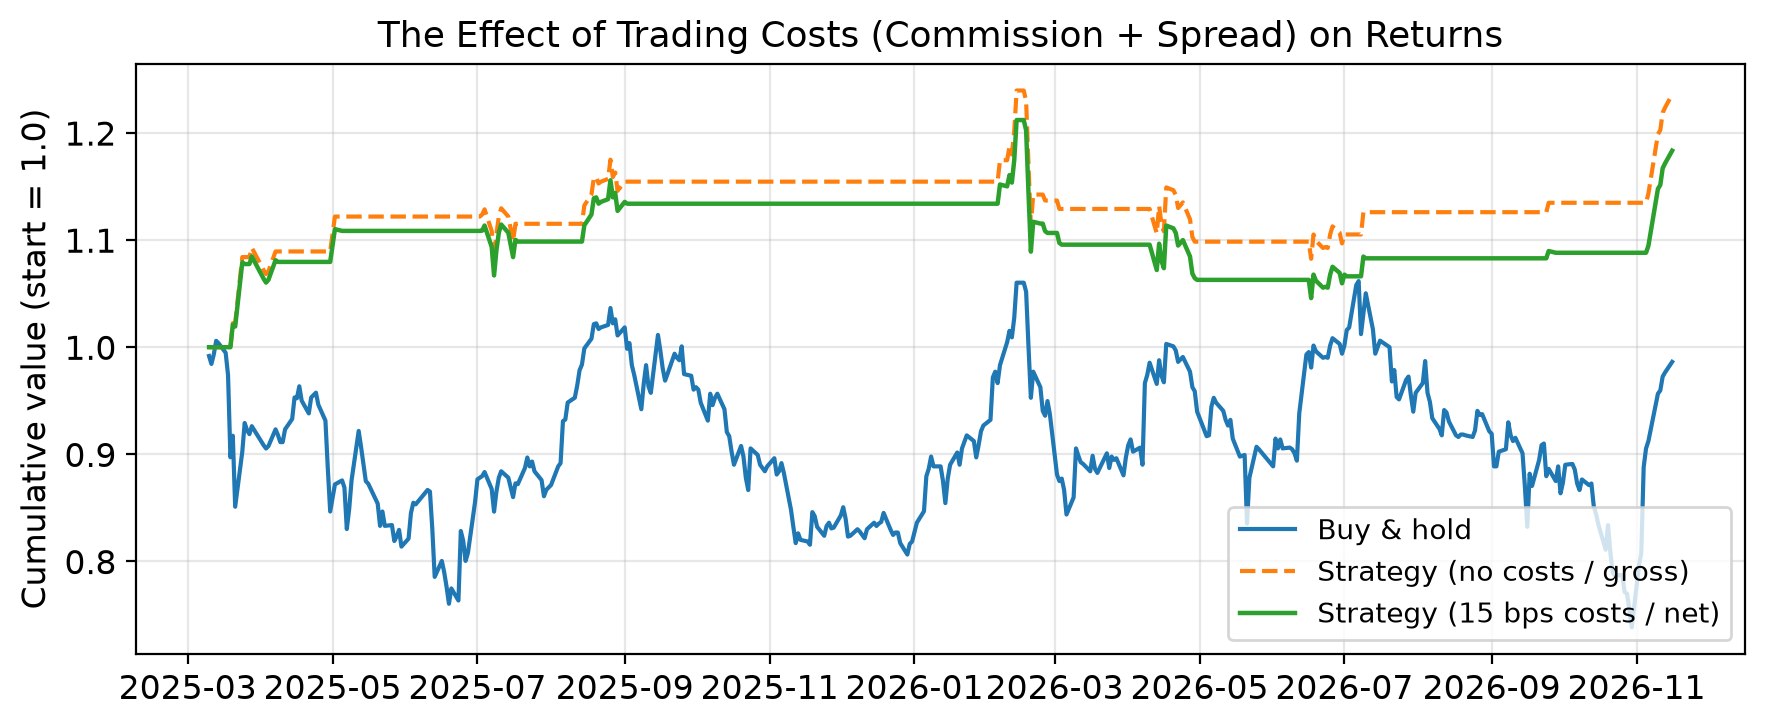

In [26]:
# @title 💡 Solution 4 (Bonus): TinyTransformer and a backtest with trading costs { display-mode: "form" }
res_tf = train_direction_classifier(
    x_train, train_df["up_day"].values,
    x_val, val_df["up_day"].values,
    x_test, test_df["up_day"].values,
    window_size=WINDOW_SIZE, epochs=12, seed=42, model_cls=TinyTransformerModel,
)
print(f"TinyTransformer -> Test Acc: {res_tf['test_acc']*100:.2f}%")

test_rets = test_df["log_return"].values[WINDOW_SIZE:]
bt = backtest_with_costs(test_rets, cls_res["y_pred"], cost_bps=15.0)
print(f"Trades: {bt['n_trades']} | Days in the market: {cls_res['y_pred'].mean():.0%} | Buy & hold: {bt['final_buy_hold']:.2f}x | "
      f"Strategy (gross): {bt['final_gross']:.2f}x | Strategy (net of costs): {bt['final_net']:.2f}x")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(test_df.index[WINDOW_SIZE:], bt["cum_buy_hold"], label="Buy & hold", linewidth=1.5)
ax.plot(test_df.index[WINDOW_SIZE:], bt["cum_gross"], label="Strategy (no costs / gross)", linestyle="--")
ax.plot(test_df.index[WINDOW_SIZE:], bt["cum_net"], label="Strategy (15 bps costs / net)", linewidth=1.6)
ax.set_title("The Effect of Trading Costs (Commission + Spread) on Returns")
ax.set_ylabel("Cumulative value (start = 1.0)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## Part 7 · Wrap-up
*⏱️ Live session: 18:40–18:45*

### Three takeaways
1. **Always compare with a naive baseline:** a deep learning model that can't beat "tomorrow = today", however complex, is just repeating yesterday's price.
2. **Split time series by time only:** random shuffling leaks the future into the past; realistic evaluation needs a chronological split and **walk-forward** validation.
3. **Data leakage hides everywhere:** from fitting the `StandardScaler` on all the data to filling missing days backwards (`bfill`), the smallest mistake produces artificially high but worthless results.

### What do real quant teams do differently?
- **Many data sources:** not just daily OHLCV; they combine order-book microstructure, company fundamentals, macroeconomic series and news/sentiment feeds.
- **Portfolio and risk management:** instead of trying to call one stock's direction, they rank hundreds of assets against each other (cross-sectional ranking) and control volatility and drawdowns.
- **Trading costs and execution:** they put commissions, the bid-ask spread and market impact (slippage) directly into the objective.

### Useful links
- 📘 **Workshop guide:** [omarcevi.dev/workshops/pytorch-finance-workshop](https://omarcevi.dev/workshops/pytorch-finance-workshop/)
- 🔥 **Official PyTorch tutorials:** [pytorch.org/tutorials](https://pytorch.org/tutorials/)
- 📏 **Scikit-Learn TimeSeriesSplit:** [scikit-learn.org/stable/modules/cross_validation.html#time-series-split](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split)

> ⚠️ **Disclaimer (Not Investment Advice):** This work and its models were prepared for academic and teaching purposes only; under no circumstances should they be taken as financial or investment advice.